<a href="https://colab.research.google.com/github/fralfaro/inf449-portafolio/blob/main/tareas/tarea-04/homework4.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

# Tarea 4: elementos difractivos y deconvolución

**Fotografía Computacional — INF-449, Universidad Técnica Federico Santa María**

Este notebook ejecuta el sistema completo solicitado en la guía: una imagen RGB pasa por un elemento óptico difractivo (fase cúbica más modos de Zernike), por un filtro Bayer RGGB y por una etapa de demosaicking. Luego se comparan Wiener y Richardson–Lucy, implementados desde cero y mediante `skimage.restoration`, y se calculan PSNR, SSIM y SAM sobre las 18 imágenes del dataset McMaster. Todo el código está en `homework4.py`; el notebook lo importa y muestra los resultados.

## 1. Modelo y protocolo

Para cada longitud de onda (650, 550 y 450 nm para R, G y B) se calcula la PSF $h_c=|\mathcal F\{A\exp(i\tfrac{\lambda_0}{\lambda}\phi)\}|^2$, donde $A$ es una apertura circular y $\phi$ combina una fase cúbica ($\alpha=18$ rad) con los modos de Zernike $Z_4$–$Z_7$ (indexación de Noll, sin normalización RMS). La medición es

$$y = \operatorname{Sensor}\left(h_R*I_R,\,h_G*I_G,\,h_B*I_B\right)_{\mathrm{Bayer}}.$$

La medición se interpola mediante demosaicking bilineal ($\widetilde I$) y cada canal se deconvoluciona con Wiener ($\tau=0.01$) o Richardson–Lucy ($K=25$ iteraciones, inicialización constante). Ambas implementaciones propias se comparan con `skimage.restoration` usando la misma imagen, PSF, $\tau$ e iteraciones; para Wiener se pasa `reg` igual a un impulso unitario, porque por defecto `skimage` regulariza con un Laplaciano (esa variante también se reporta como referencia). Las imágenes de McMaster son de 500×500 píxeles; se redimensionan a 256×256 para que el experimento sea reproducible en CPU.

## 2. Preparación del entorno

La celda siguiente funciona en Jupyter local y en Google Colab:

- si `homework4.py` está en el directorio actual o en `tareas/tarea-04`, se usa esa copia;
- en caso contrario (por ejemplo, en Colab), se clona el repositorio del curso;
- se instalan solo las dependencias que falten.

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

REPO_URL = 'https://github.com/fralfaro/inf449-portafolio.git'
candidates = [Path('.'), Path('tareas/tarea-04'), Path('inf449-portafolio/tareas/tarea-04')]
TASK_DIR = next((p for p in candidates if (p / 'homework4.py').exists()), None)
if TASK_DIR is None:
    subprocess.run(['git', 'clone', '--depth', '1', REPO_URL], check=True)
    TASK_DIR = Path('inf449-portafolio/tareas/tarea-04')
TASK_DIR = TASK_DIR.resolve()

required = {'numpy': 'numpy', 'scipy': 'scipy', 'skimage': 'scikit-image',
            'matplotlib': 'matplotlib', 'PIL': 'Pillow', 'certifi': 'certifi', 'pandas': 'pandas'}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

sys.path.insert(0, str(TASK_DIR))
print('Directorio de la tarea:', TASK_DIR)

Directorio de la tarea: /Users/franciscoalfaro/Documents/00_fralfaro/inf449-portafolio/tareas/tarea-04


## 3. Ejecución del experimento

`run_experiment` descarga McMaster si no está en `data/McMaster`, simula las 18 imágenes, guarda las figuras en `Fig/` y los resultados en `resultados/` (`metricas_mcmaster.csv`, `diagnosticos_por_imagen.csv`, `barrido_parametros.csv` y las tablas `.tex` del informe). La ejecución completa, con el barrido de $\tau$ y de iteraciones, tarda unos dos minutos en CPU. Con `EJECUTAR = False` se leen los CSV ya generados.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import homework4 as hw

EJECUTAR = True
if EJECUTAR:
    hw.run_experiment(size=256, iterations=25, balance=0.01)

results = pd.read_csv(hw.METRICS_CSV)
diagnostics = pd.read_csv(hw.DIAGNOSTICS_CSV)
sweep = pd.read_csv(hw.SWEEP_CSV)
metrics = ['PSNR [dB]', 'SSIM', 'SAM [deg]']
summary = results.groupby('metodo', sort=False)[metrics].agg(['mean', 'std'])
display(summary.round(4))

[01/18] 1.png


[02/18] 2.png


[03/18] 3.png


[04/18] 4.png


[05/18] 5.png


[06/18] 6.png


... (22 outputs left out)

Barrido iteraciones=50: PSNR 16.56 dB


Barrido iteraciones=100: PSNR 12.30 dB


Resultados guardados en /Users/franciscoalfaro/Documents/00_fralfaro/inf449-portafolio/tareas/tarea-04/resultados/metricas_mcmaster.csv


PSNR [dB]            SSIM         SAM [deg]        
                        mean     std    mean     std      mean     std
metodo                                                                
demosaic             16.6766  1.9344  0.3965  0.1287    7.9700  2.9778
wiener_scratch       19.4454  2.1639  0.6259  0.0829    8.4289  2.3957
wiener_skimage       19.4454  2.1639  0.6259  0.0829    8.4289  2.3957
wiener_skimage_lap   20.0772  2.1993  0.6626  0.0761    7.5708  2.2446
rl_scratch           18.3848  2.2139  0.6440  0.0859    8.1727  1.6115
rl_skimage           18.3848  2.2139  0.6440  0.0859    8.1727  1.6115

## 4. Implementación propia frente a `skimage`

Máxima diferencia absoluta por píxel entre reconstrucciones (sobre las 18 imágenes) y máxima diferencia en cada métrica.

In [3]:
pairs = {
    'Wiener (tau constante)': ('wiener_scratch', 'wiener_skimage', 'dif_max_wiener'),
    'Wiener vs. skimage Laplaciano': ('wiener_scratch', 'wiener_skimage_lap', 'dif_max_wiener_lap'),
    'Richardson-Lucy': ('rl_scratch', 'rl_skimage', 'dif_max_rl'),
}
table = {}
for name, (own, ref, column) in pairs.items():
    a = results[results.metodo == own].set_index('imagen')[metrics]
    b = results[results.metodo == ref].set_index('imagen')[metrics]
    row = {'max |dif. píxel|': diagnostics[column].max()}
    row.update({f'max |dif. {m}|': (a - b).abs().max()[m] for m in metrics})
    table[name] = row
display(pd.DataFrame(table).T)

,max |dif. píxel|,max |dif. PSNR [dB]|,max |dif. SSIM|,max |dif. SAM [deg]|
Wiener (tau constante),1.776357e-15,3.552714e-15,1.465494e-14,2.131628e-14
Wiener vs. skimage Laplaciano,7.721500e-01,1.008081e+00,4.981810e-02,1.357059e+00
Richardson-Lucy,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


## 5. Métricas por imagen en todo el dataset

PSNR y SSIM: mayor es mejor. SAM (en grados; la guía lo define en radianes): menor es mejor.

In [4]:
for metric in metrics:
    pivot = results.pivot(index='imagen', columns='metodo', values=metric)
    display(pivot[['demosaic', 'wiener_scratch', 'rl_scratch', 'wiener_skimage_lap']]
            .round(3).rename_axis(metric, axis=1))

PSNR [dB],demosaic,wiener_scratch,rl_scratch,wiener_skimage_lap
imagen,,,,
1,13.742,17.171,16.622,17.702
2,15.802,20.361,20.098,20.838
3,14.659,16.314,15.097,16.861
4,13.099,13.878,12.599,14.450
5,15.933,18.726,17.539,19.339
6,17.694,19.864,18.436,20.489
7,16.344,20.238,18.640,21.004
8,17.406,20.824,19.961,21.445
9,17.444,19.432,17.802,20.220


SSIM,demosaic,wiener_scratch,rl_scratch,wiener_skimage_lap
imagen,,,,
1,0.241,0.538,0.576,0.586
2,0.406,0.671,0.697,0.701
3,0.238,0.473,0.477,0.517
4,0.285,0.489,0.478,0.539
5,0.326,0.617,0.618,0.660
6,0.330,0.614,0.629,0.655
7,0.360,0.569,0.622,0.606
8,0.472,0.702,0.770,0.727
9,0.465,0.657,0.662,0.694


SAM [deg],demosaic,wiener_scratch,rl_scratch,wiener_skimage_lap
imagen,,,,
1,11.252,9.218,8.938,8.342
2,9.255,8.595,8.163,7.903
3,9.577,10.328,10.982,9.255
4,4.182,6.388,7.683,5.431
5,7.744,7.668,8.401,6.865
6,7.961,7.494,8.327,6.593
7,4.619,9.036,7.567,8.066
8,11.105,15.841,11.736,14.484
9,7.732,8.024,7.652,7.183


## 6. Barrido de parámetros y estimación de $\tau$ según la ecuación (5)

La estimación escalar $\tau\approx\|\widetilde I-\bar I\|_2^2/\|I\|_2^2$ supone espectros planos; el barrido muestra que el valor útil es mucho mayor, porque el error del demosaicking se concentra en altas frecuencias.

In [5]:
print('tau estimado (ec. 5): media {:.2e}, rango [{:.2e}, {:.2e}]'.format(
    diagnostics.tau_ec5.mean(), diagnostics.tau_ec5.min(), diagnostics.tau_ec5.max()))
print('Fracción de energía con frecuencia > 0.25 ciclos/píxel: error {:.1%}, señal {:.1%}'.format(
    diagnostics.frac_alta_frec_error.mean(), diagnostics.frac_alta_frec_senal.mean()))
display(sweep.round(4))

tau estimado (ec. 5): media 1.80e-04, rango [8.02e-05, 3.67e-04]
Fracción de energía con frecuencia > 0.25 ciclos/píxel: error 55.0%, señal 1.0%


,parametro,valor,metodo,PSNR [dB],SSIM,SAM [deg]
0,tau,0.0001,wiener_scratch,16.9272,0.4766,14.5499
1,tau,0.0003,wiener_scratch,17.5952,0.5265,12.8877
2,tau,0.0010,wiener_scratch,18.4079,0.5781,10.9237
3,tau,0.0030,wiener_scratch,18.9471,0.6115,9.5882
4,tau,0.0100,wiener_scratch,19.4454,0.6259,8.4289
5,tau,0.0300,wiener_scratch,19.6611,0.6170,7.7089
6,tau,0.1000,wiener_scratch,18.8493,0.5781,7.2987
7,iteraciones,5.0000,rl_scratch,19.2069,0.5787,5.6941
8,iteraciones,10.0000,rl_scratch,19.1699,0.6202,5.9995
9,iteraciones,25.0000,rl_scratch,18.3848,0.6440,8.1727


## 7. Figuras

Las figuras se leen desde `Fig/` y se muestran con `plt.imshow`.

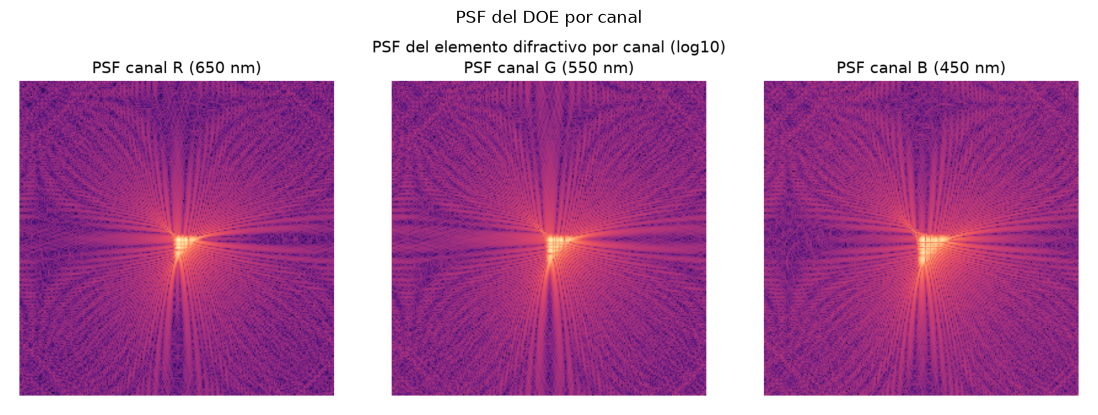

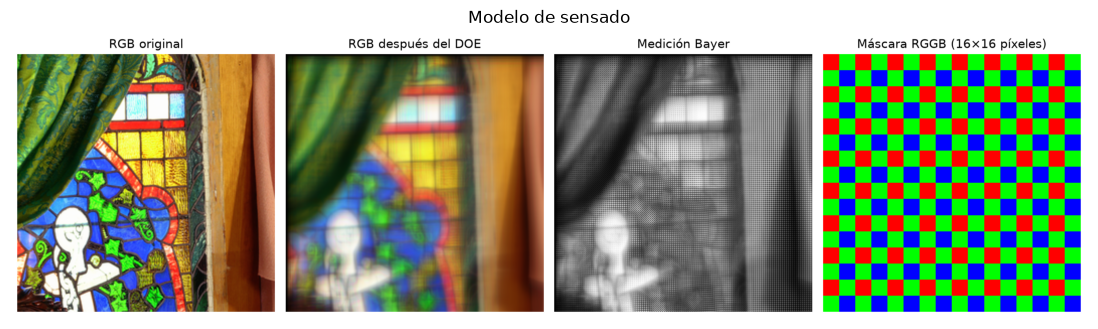

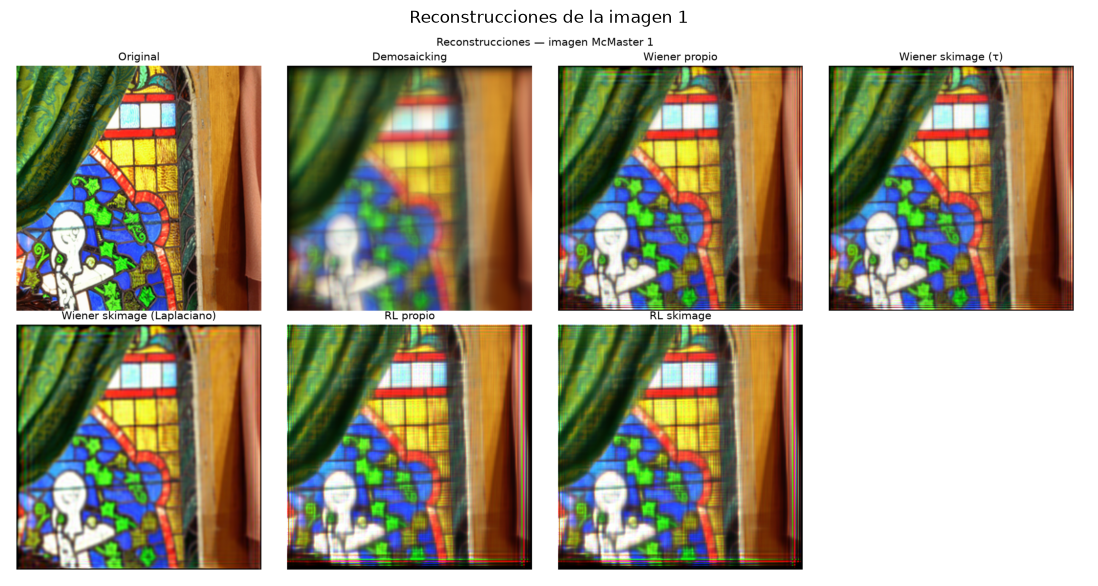

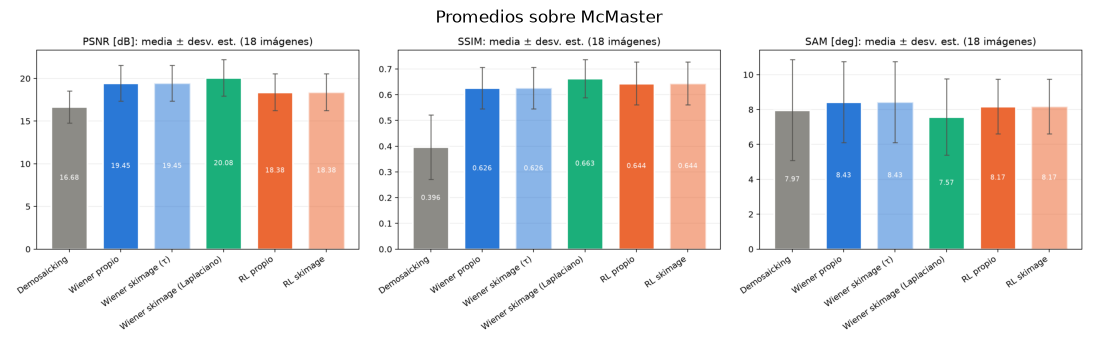

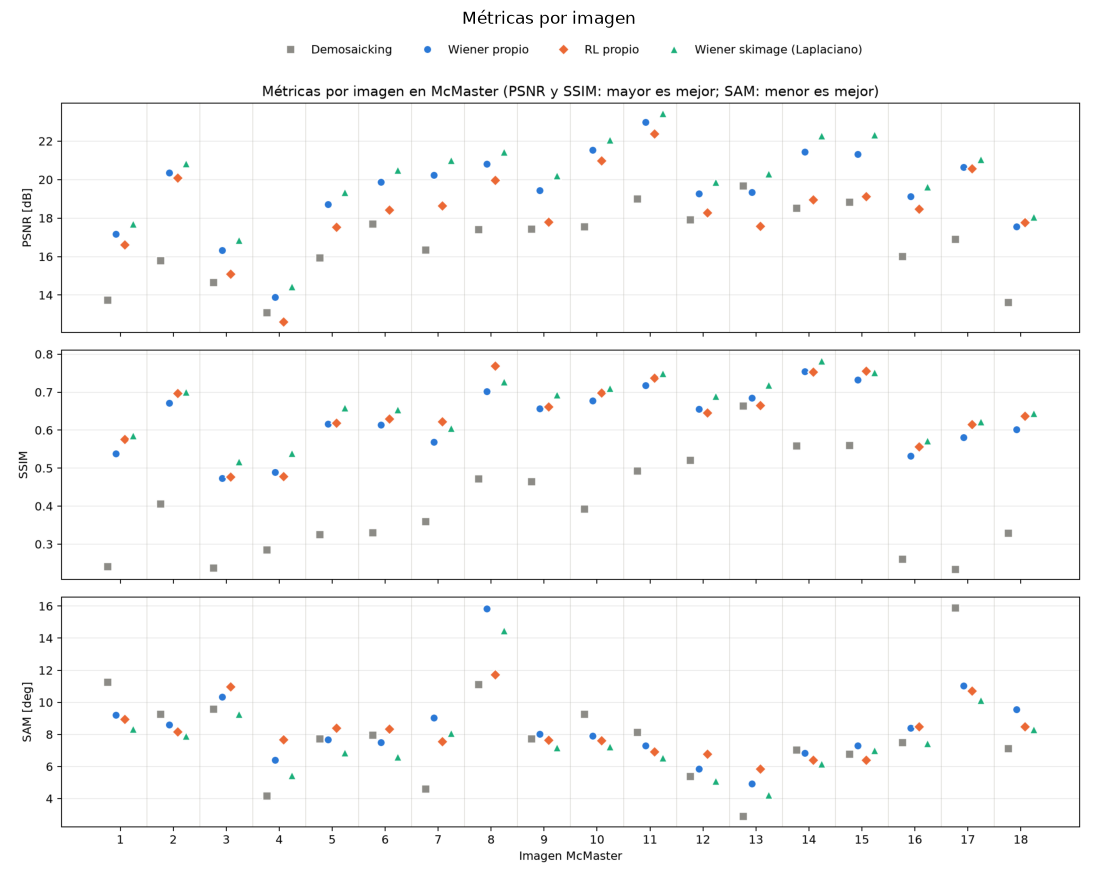

In [6]:
figures = [
    ('psf_doe.png', 'PSF del DOE por canal'),
    ('modelo_sensor.png', 'Modelo de sensado'),
    ('reconstruccion_ejemplo.png', 'Reconstrucciones de la imagen 1'),
    ('metricas_dataset.png', 'Promedios sobre McMaster'),
    ('metricas_por_imagen.png', 'Métricas por imagen'),
]
for filename, title in figures:
    image = plt.imread(TASK_DIR / 'Fig' / filename)
    height, width = image.shape[:2]
    fig, ax = plt.subplots(figsize=(14, 14 * height / width))
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')
    plt.show()

## 8. Lectura de resultados

- Wiener ($\tau=0.01$) obtiene el mayor PSNR medio entre los métodos propios y RL ($K=25$) el mayor SSIM medio.
- Ningún método con $\tau$ constante ni RL mejora el SAM medio del demosaicking; la deconvolución independiente por canal introduce franjas de color.
- Con la misma formulación, las implementaciones propias reproducen a `skimage` hasta la precisión de máquina.

La discusión completa, con las cifras por imagen, está en `informe.pdf`.